# 06 — Sequential feature selection (Bogotá)

Mirrors Bety's §2.6: cross-validated neural-net sequential *forward* feature selection
over the candidate pool built in notebook 05. Starting from an empty set, at each step we
add whichever remaining candidate feature most improves cross-validated R², producing a
Pareto front of R² vs. number of features.

Cross-validation here is **leave-one-year-out (LOYO)** across the ~12 years of Bogotá
data — the analogue of Bety's leave-one-regime-out across their 5 RCE simulations: each
year had different meteorology/policy, so generalizing across years is evidence a feature
captures something real rather than a within-year artifact.

We run this **twice**: with and without `pm25_lag1` (the autoregressive term) in the
candidate pool, since a same-pollutant lag tends to dominate feature selection and can
mask the physical (meteorological/emissions) drivers we're actually trying to identify.

**Revised** (v2): the first pass through this notebook included PM10, NO2 and O3 as
candidates and found PM10 dominated everything (R²=0.85 alone). On reflection this was a
methodological mistake, not just a nuisance correlation: **PM2.5 is a physical subset of
PM10** by particle-size definition, so PM10 "predicting" PM2.5 is close to data leakage,
not a discovered relationship. O3 is also excluded now — it's a secondary photochemical
product formed downstream of NOx and sunlight, not an independent causal driver. NO2 is
kept, since it's a primary emission product (a real proxy for vehicular/combustion source
strength) that isn't derived from PM2.5 or PM10 at all. See the exclusion cell below.

**Revised again** (v5): the "no-lag" run below previously included raw calendar terms
(`doy_sin`/`doy_cos`/`month_sin`/`month_cos`) and they dominated the selection —
user pushback: "having the seasons is basically not telling me anything." A fast
XGBoost screen (notebook 05b) found that removing those calendar terms costs ~no
predictive power once fire-hotspot features are available (their combined importance
share jumps to 34%), suggesting SFS's greedy one-at-a-time algorithm was simply never
giving the (individually weaker, collectively strong) fire-region features a fair shot
against a single clean calendar predictor. The "no-lag" run now excludes calendar terms
entirely, forcing LOYO-CV to test that substitution claim rigorously rather than in a
single train/test split.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

DATA_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "bogota"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "bogota" / "figures"

df = pd.read_parquet(DATA_DIR / "bogota_master_dataset.parquet")
df = df.dropna(subset=['pm25']).reset_index(drop=True)
df['year'] = df['date'].dt.year
print(df.shape)
df['year'].value_counts().sort_index()


(4383, 216)


year
2014    365
2015    365
2016    366
2017    365
2018    365
2019    365
2020    366
2021    365
2022    365
2023    365
2024    366
2025    365
Name: count, dtype: int64

In [2]:
EXCLUDE = {'date', 'pm25', 'year', 'season'}  # 'season' is a string label (DJF/MAM/...)
# from notebook 05's verification cell -- redundant with month_sin/month_cos anyway.

# Causal exclusions (user-flagged, correctly): PM10 and PM2.5 aren't just correlated
# pollutants -- PM2.5 is a physical SUBSET of PM10 by particle-size definition, so using
# PM10 to "predict" PM2.5 is close to data leakage, not a discovered relationship (this
# is confirmed by the earlier run: PM10 alone got R2=0.85 immediately). O3 is a secondary
# photochemical product formed from NOx + sunlight (and is titrated by fresh NO), so it's
# downstream of, not causally prior to, combustion emissions -- it's not an independent
# driver either. NO2 is kept: it's a primary emission product (a genuine proxy for
# vehicular/combustion source strength) that isn't derived from PM2.5 or PM10 at all.
CAUSAL_EXCLUDE = {c for c in df.columns if c == 'pm10' or c.startswith('pm10_lag')}
CAUSAL_EXCLUDE |= {c for c in df.columns if c == 'o3' or c.startswith('o3_lag')}
EXCLUDE |= CAUSAL_EXCLUDE
print(f"Excluding as non-causal (PM10 is definitionally part of PM2.5; O3 follows NO2, not a driver): {sorted(CAUSAL_EXCLUDE)}")

ALL_CANDIDATES = [c for c in df.columns if c not in EXCLUDE]
print(f"{len(ALL_CANDIDATES)} total candidate columns")

# Require a candidate to have enough non-null coverage to be usable; SFS drops rows with
# any NaN in the active feature set, so a very sparse candidate would gut the sample size.
# NOTE: the fire-hotspot columns are ~83% complete (the hotspot product stops at
# end-2023, ~17% short of the 2014-2025 record); the new wind-transport-weighted hotspot
# variants (region count x wind alignment) additionally depend on wind_dir (~92% complete)
# and land at 74.99% coverage -- a hair under a naive 0.75 cutoff purely by rounding
# coincidence. 0.70 keeps those and pressure/hotspots (~83%) while still dropping
# genuinely sparse columns like temp_10m/rh_10m (~25% complete, only a few stations
# report a 10m sensor).
MIN_COVERAGE = 0.70
coverage = df[ALL_CANDIDATES].notna().mean()
CANDIDATES = coverage[coverage >= MIN_COVERAGE].index.tolist()
print(f"{len(CANDIDATES)} candidates meet >={MIN_COVERAGE:.0%} coverage")
dropped = sorted(set(ALL_CANDIDATES) - set(CANDIDATES))
print("Dropped for low coverage:", dropped)


Excluding as non-causal (PM10 is definitionally part of PM2.5; O3 follows NO2, not a driver): ['o3', 'o3_lag1', 'o3_lag2', 'o3_lag3', 'pm10', 'pm10_lag1', 'pm10_lag2', 'pm10_lag3']
204 total candidate columns
194 candidates meet >=70% coverage
Dropped for low coverage: ['nox', 'nox_lag1', 'nox_lag2', 'nox_lag3', 'rh_10m', 'so2', 'so2_lag1', 'so2_lag2', 'so2_lag3', 'temp_10m']


## LOYO cross-validated forward feature selection

In [3]:
from common.feature_selection import loyo_r2, sequential_forward_selection
# Parallelized across candidates within each SFS step (joblib, n_jobs=8) -- the earlier
# single-core inline version was killed after 2+ hours with nothing ever saved (204
# candidates is a lot for a sequential loop). See common/feature_selection.py.

In [4]:
print("=== SFS including pm25_lag1 ===")
selected_with_lag, scores_with_lag = sequential_forward_selection(df, CANDIDATES, target='pm25', n_jobs=8)


=== SFS including pm25_lag1 ===


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


... (21 outputs left out)

  + wind_speed_era5                     -> across-year R2 = 0.820


  + is_weekend                          -> across-year R2 = 0.824


  + wind_speed_lag1                     -> across-year R2 = 0.829


  + lts_morning                         -> across-year R2 = 0.831


In [5]:
print("=== SFS excluding pm25_lag1 AND raw calendar terms (forcing physical substitutes) ===")
# A quick XGBoost screen (05b) showed removing doy_sin/doy_cos/month_sin/month_cos costs
# ~nothing (R2 0.361 -> 0.380) once the fire-hotspot features are available -- their
# combined importance share jumps to 34% of the model, up from being unselected
# entirely. That's a real result, but it's a single train/test split with a
# not-cross-validated importance metric; SFS's greedy one-feature-at-a-time algorithm
# also structurally favors a single clean predictor (day-of-year) over many individually
# -weaker-but-collectively-strong ones (6 fire regions x lags x transport variants), so
# the earlier "no-lag" run above never gave them a fair chance. This run removes the
# calendar shortcut entirely so LOYO-CV can rigorously test whether the fire/wind/LTS
# features actually substitute for it, not just correlate with it in one split.
CALENDAR_COLS = {'doy_sin', 'doy_cos', 'month_sin', 'month_cos'}
candidates_no_lag = [c for c in CANDIDATES if c not in CALENDAR_COLS | {'pm25_lag1'}]
selected_no_lag, scores_no_lag = sequential_forward_selection(df, candidates_no_lag, target='pm25', n_jobs=8)


=== SFS excluding pm25_lag1 AND raw calendar terms (forcing physical substitutes) ===


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


... (19 outputs left out)

  + hotspots_sector_N                   -> across-year R2 = 0.704


  + sensible_heat_flux                  -> across-year R2 = 0.712


  + blh_mean                            -> across-year R2 = 0.719


  + hotspots_sector_E_lag2              -> across-year R2 = 0.724


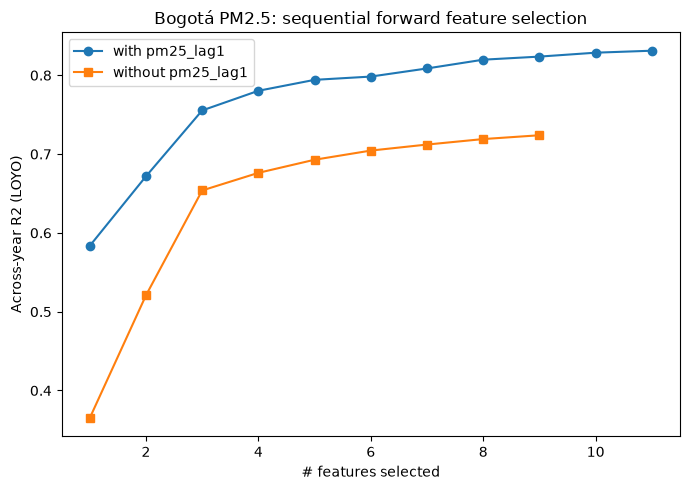

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(range(1, len(scores_with_lag) + 1), scores_with_lag, marker='o', label='with pm25_lag1')
ax.plot(range(1, len(scores_no_lag) + 1), scores_no_lag, marker='s', label='without pm25_lag1')
ax.set_xlabel('# features selected')
ax.set_ylabel('Across-year R2 (LOYO)')
ax.set_title('Bogotá PM2.5: sequential forward feature selection')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'sfs_pareto_front.png', dpi=150)
plt.show()


## Save selected feature sets for equation discovery

In [7]:
import json

result = {
    'selected_with_lag': selected_with_lag,
    'scores_with_lag': scores_with_lag,
    'selected_no_lag': selected_no_lag,
    'scores_no_lag': scores_no_lag,
}
out_path = DATA_DIR / "bogota_feature_selection.json"
with open(out_path, 'w') as f:
    json.dump(result, f, indent=2)
print("Saved:", out_path)
print(result)


Saved: /path/to/project/Data/processed/colombia/bogota/bogota_feature_selection.json
{'selected_with_lag': ['pm25_lag1', 'co', 'co_lag1', 'w700', 'hotspots_sector_NE_lag1', 'wind_dir_sin', 'sensible_heat_flux', 'wind_speed_era5', 'is_weekend', 'wind_speed_lag1', 'lts_morning'], 'scores_with_lag': [0.583457695046157, 0.6717044078393881, 0.7553415734384038, 0.780294929090761, 0.7941711080909619, 0.7983202155402771, 0.8086289784249967, 0.8197533060995631, 0.8236653796334812, 0.8286304163667748, 0.8311442248365999], 'selected_no_lag': ['w700', 'co', 'hotspots_sector_NE_lag2', 'sensible_heat_flux_lag1', 'wind_speed_era5', 'hotspots_sector_N', 'sensible_heat_flux', 'blh_mean', 'hotspots_sector_E_lag2'], 'scores_no_lag': [0.36494416428738885, 0.5206440731222968, 0.6538188982064266, 0.6761561357479057, 0.6927957380593133, 0.7044245386696153, 0.7120646009210883, 0.7190275212940016, 0.7238701342112207]}
